### **Configuração Pasta Raiz**

In [1]:
import sys
import os

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))

# Adiciona a raiz do projeto ao path do Python para que as importações funcionem
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

# print(f"Raiz do projeto definida como: {PROJECT_ROOT}")

In [2]:
import pandas as pd                                                                # Manipulação de dados
import numpy as np                                                                 # Realização de cálculos específicos
import matplotlib.pyplot as plt                                                    # Visualização de dados 
import seaborn as sns                                                              # Visualização de dados
import time                                                                        # Cálculo de tempo de execução
import math                                                                        # Funções matemáticas
from scipy.stats import randint, uniform, loguniform                               # Geração de valores aleatórios
from sklearn.compose import ColumnTransformer                                      # Transformação de colunas
from sklearn.preprocessing import StandardScaler, OneHotEncoder                    # Transformação de colunas
from sklearn.base import clone                                                     # Criação de cópias de modelos
from sklearn.model_selection import train_test_split                               # Validação simples
from imblearn.under_sampling import RandomUnderSampler                             # Subamostragem
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV            # Validação cruzada e estratificação de folds
from sklearn.utils.class_weight import compute_sample_weight                       # Cálculo de pesos para observações
from sklearn.linear_model import SGDClassifier                                     # Regressão logística com regularização
from sklearn.tree import DecisionTreeClassifier                                    # Árvore de decisão
from sklearn.ensemble import RandomForestClassifier                                # Floresta aleatória
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier        # Impulsionamento tradicional
from sklearn.ensemble import HistGradientBoostingClassifier                        # Impulsionamento com histogramas
from xgboost import XGBClassifier                                                  # Impulsionamento via XGBoost
from lightgbm import LGBMClassifier                                                # Impulsionamento via LightGBM
from sklearn.calibration import CalibratedClassifierCV                             # Calibração de probabilidades
from sklearn.calibration import calibration_curve                                  # Gráfico de curva de calibração
from sklearn.metrics import brier_score_loss                                       # Score de Brier
from sklearn.preprocessing import label_binarize                                   # Binarização da resposta (Score de Brier one-vs-rest)
from sklearn.metrics import confusion_matrix                                       # Análise de desempenho: matriz de classificação
from sklearn.metrics import accuracy_score, balanced_accuracy_score                # Análise de desempenho: acurácia e acurácia balanceada
from sklearn.metrics import get_scorer, auc, roc_auc_score, roc_curve              # Análise de desempenho: KS e AUC
from sklearn.inspection import permutation_importance                              # Importância de variáveis por permutação
import shap                                                                        # Interpretabilidade de variáveis nos modelos

### **Leitura da base de dados**

In [3]:
FILES = {
    'all_players': "data/01_final_dataset_merged.csv",
    'college_players': "data/02_college_players_dataset.csv",
    'college_players_before_2021': "data/03_college_players_before_2021_dataset.csv",
    'college_players_after_2021': "data/04_college_players_after_2021_dataset.csv",
    'college_players_after_2021_dropped': "data/05_college_players_after_2021_dropped_dataset.csv",
    'final': "data/00_final_dataset.csv"
}

In [4]:
dfs = {}

for key, filename in FILES.items():
    file_path = f'../{filename}'
    
    try:
        dfs[key] = pd.read_csv(file_path)
        
        print(f"✅ {key.ljust(15)}: Carregado ({len(dfs[key])} linhas)")
        
    except FileNotFoundError:
        print(f"❌ {key.ljust(15)}: Arquivo não encontrado em '{file_path}'")
    except Exception as e:
        print(f"❌ {key.ljust(15)}: Erro - {e}")

✅ all_players    : Carregado (1542 linhas)
✅ college_players: Carregado (1183 linhas)
✅ college_players_before_2021: Carregado (954 linhas)
✅ college_players_after_2021: Carregado (229 linhas)
✅ college_players_after_2021_dropped: Carregado (229 linhas)
✅ final          : Carregado (954 linhas)


In [5]:
dados = dfs['final'].copy()

### **Etapa 1: Especificação de variáveis**

*Lista de nomes das variáveis explicativas, separando em quantitativas e qualitativas*

In [6]:
# Variáveis explicativas quantitativas (deixar vazio [] caso não haja nenhuma)
lista_X_quanti = [
  # --- Informações Físicas e do Draft ---
    'draft_year', 
    'draft_age', 
    'years_college', 
    'mock_pick',        # Expectativa do mercado antes do draft
    'height_cm', 
    'weight_kg',

    # --- Estatísticas Avançadas (Eficiência) ---
    'true_shooting_pct', 
    'effective_field_goal_pct', 
    'usage_pct',
    'offensive_win_shares', 
    'defensive_win_shares', 
    'win_shares_per_40min',
    'three_point_attempt_rate', 
    'free_throw_attempt_rate',

    # --- Estatísticas de Arremesso (Volume e Precisão) ---
    'field_goal_attempted', 
    'three_pointers_made', 
    'three_pointers_attempted', 
    'three_point_pct',
    'free_throw_attempted', 
    'free_throw_pct',

    # --- Estatísticas Tradicionais (Médias por Jogo) ---
    'points', 
    'assists', 
    'total_rebounds', 
    'offensive_rebounds', 
    'defensive_rebounds',
    'steals', 
    'blocks', 
    'turnovers', 
    'personal_fouls',

    # --- Experiência no College (Acumulados) ---
    'career_games', 
    'career_starts', 
    'career_minutes', 
    'career_awards_count'
]

# Variáveis explicativas qualitativas (deixar vazio [] caso não haja nenhuma)
lista_X_quali = [
    # 'college_name', 
    # 'conference', 
    'position'
]

*Objetos para variável resposta (y) e explicativas (X)*

In [7]:
y = dados['target_label']
X = dados[lista_X_quali + lista_X_quanti]

In [8]:
# Ordenando as categorias da resposta y
ordem_categorias = ['Bust', 'Rotation', 'Starter', 'Star']
y = y.astype(pd.CategoricalDtype(categories=ordem_categorias, ordered=True))

### **Etapa 2: Divisão de treino e teste externo**

*Divisão inicial*

In [9]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y,
                                                        test_size=0.2,
                                                        stratify=y,
                                                        random_state=123)

*Representação das categorias de y como números (requerido por alguns algoritmos e para calibração)*

In [10]:
y_treino = y_treino.astype(pd.CategoricalDtype(categories=ordem_categorias, ordered=True)).cat.codes.rename(y.name)
y_teste = y_teste.astype(pd.CategoricalDtype(categories=ordem_categorias, ordered=True)).cat.codes.rename(y.name)

In [11]:
y_treino.value_counts()

target_label
0    397
1    221
2    103
3     42
Name: count, dtype: int64

### **Etapa 3: Pré-processamento de variáveis explicativas**

*Definição das funções de pré-processamento: Padronização das variáveis quantitativas + Codificação one-hot para variáveis qualitativas*

In [12]:
preprocessador = ColumnTransformer(transformers=[
    ("quanti", StandardScaler(), lista_X_quanti),
    ("quali", OneHotEncoder(sparse_output=False, drop="first", handle_unknown='ignore'), lista_X_quali)
],
    remainder="passthrough"
)

*Criação do pré-processamento no conjunto de treino* <br>

In [13]:
X_treino_tratada = preprocessador.fit_transform(X_treino)  # O pré-processamento não deve envolver o conjunto de teste externo, que deve ficar reservado apenas para aplicações de resultados já obtidos, e nunca construções
if lista_X_quali:
    nomes_quali = list(preprocessador.named_transformers_['quali'].get_feature_names_out(lista_X_quali))
else:
    nomes_quali = []
nomes_variaveis = list(lista_X_quanti) + nomes_quali

In [14]:
X_treino_tratada = pd.DataFrame(X_treino_tratada, columns=nomes_variaveis)
X_treino_tratada.head()

,draft_year,draft_age,years_college,mock_pick,height_cm,weight_kg,true_shooting_pct,effective_field_goal_pct,usage_pct,offensive_win_shares,...,steals,blocks,turnovers,personal_fouls,career_games,career_starts,career_minutes,career_awards_count,position_Forward,position_Guard
0,0.929730,0.318081,1.031384,0.042123,-0.062836,-1.005609,1.264503,1.024746,0.317420,-0.584000,...,-0.277224,-0.799885,-0.863107,-1.587245,0.388005,0.004949,0.231559,-0.529622,0.0,1.0
1,-1.393942,1.023593,1.031384,0.456826,-1.135495,0.067339,1.415145,0.762118,-0.686887,1.232272,...,1.307210,-0.486301,0.165276,0.434384,0.977796,0.669553,0.976091,-0.529622,0.0,1.0
2,0.431800,1.729105,1.031384,1.545421,1.395497,1.838138,0.532816,1.024746,-0.082525,0.702526,...,-1.069441,-0.251113,-0.220368,0.546697,1.192265,0.216414,0.267585,1.358703,1.0,0.0
3,1.095707,-1.798454,-1.594687,-0.579932,0.925456,0.686682,-0.134311,0.461972,-0.349156,-1.113746,...,-1.227884,0.454450,0.422372,-0.464118,-1.488601,-1.112794,-1.301844,-0.529622,1.0,0.0
4,-1.061989,0.318081,1.031384,1.545421,-0.605192,-0.961993,0.317614,0.161825,-1.424564,-0.129932,...,-0.118781,-0.878280,0.808015,-0.913369,1.058222,1.696668,1.493384,1.358703,0.0,1.0


*Aplicação do pré-processamento no conjunto de teste externo*

In [15]:
X_teste_tratada = preprocessador.transform(X_teste)  # Note que o mesmo objeto de pré-processamento deve ser utilizado, agora com 'transform' em vez de 'fit_transform'
X_teste_tratada = pd.DataFrame(X_teste_tratada, columns=nomes_variaveis)
X_teste_tratada.head()

,draft_year,draft_age,years_college,mock_pick,height_cm,weight_kg,true_shooting_pct,effective_field_goal_pct,usage_pct,offensive_win_shares,...,steals,blocks,turnovers,personal_fouls,career_games,career_starts,career_minutes,career_awards_count,position_Forward,position_Guard
0,-0.398083,0.318081,1.031384,0.197636,0.009478,-0.604344,-0.349513,-0.719854,-1.771183,-0.432644,...,0.990323,-0.329509,0.550919,-0.801056,0.870561,1.001855,1.045371,-0.529622,0.0,1.0
1,0.265824,-1.798454,-1.594687,-1.461176,-0.062836,0.651790,-0.155831,-0.569781,-0.793539,0.324136,...,-0.277224,-0.094322,-0.091820,0.097446,-1.300941,-0.931538,-1.131877,1.358703,1.0,0.0
2,-0.564059,0.318081,1.031384,0.923367,-0.677506,-0.682852,-0.521675,-0.363431,-0.326936,-0.659678,...,1.624097,-0.643093,-0.220368,0.209758,0.602475,0.065368,0.480968,-0.529622,0.0,1.0
3,1.427660,1.023593,1.031384,0.353150,-0.376197,-0.464774,0.554336,0.293139,-1.482334,0.172780,...,-0.910998,-0.721489,-0.863107,-0.239493,1.379926,0.941437,1.061998,-0.529622,0.0,1.0
4,-1.227966,0.318081,1.031384,1.545421,0.093844,-0.211802,2.082272,1.718834,-0.082525,1.686340,...,0.514993,-0.329509,-0.477463,0.322071,1.058222,0.760181,0.988100,1.358703,1.0,0.0


### **Etapa 4: Definição do algoritmo e intervalos de busca de hiperparâmetros**

In [16]:
min_samples_split = randint(20, 100)
min_samples_leaf = randint(10, 50)

In [17]:
algoritmos = {

    'REGRESSÃO LOGÍSTICA REGULARIZADA': (SGDClassifier(random_state=123, loss='log_loss', max_iter=10000, tol=1e-3), {
        'penalty': ['l2', 'l1', 'elasticnet'],
        'alpha': loguniform(1e-5, 1e1),               # Peso da penalização
        'l1_ratio': uniform(0, 1),                    # Contribuição da penalização LASSO (L1) em relação a Ridge (L2)
        'eta0': loguniform(1e-4, 1e-1),               # Taxa de aprendizado inicial
        'learning_rate': ['constant',                 # Atualização de eta0: manter sempre constante
                          'invscaling',               # Atualização de eta0: reduzir gradativamente ao longo das iterações
                          'adaptive']                 # Atualização de eta0: reduzir gradativamente ao longo das iterações, se não houver redução do erro
    }),

    'ÁRVORE DE DECISÃO': (DecisionTreeClassifier(random_state=123), {
        'criterion': ['gini', 'entropy'],             # Critério de impureza
        'min_impurity_decrease': uniform(0, 0.05),    # Valor mínimo de redução de impureza
        'min_samples_split': min_samples_split,       # Qtde. mínima de observações no nó "pai" (ATENÇÃO: depende do tamanho da base)
        'min_samples_leaf': min_samples_leaf,         # Qtde. mínima de observações no nó "filho" (ATENÇÃO: depende do tamanho da base)
        'max_depth': randint(2, 11)                   # Profundidade máxima da árvore
    }),

    'FLORESTA ALEATÓRIA': (RandomForestClassifier(random_state=123, n_jobs = -1), {
        'n_estimators': randint(10, 301),             # Qtde. de árvores na floresta
        'min_impurity_decrease': uniform(0, 0.05),    # Valor mínimo de redução de impureza
        'min_samples_split': min_samples_split,       # Qtde. mínima de observações no nó "pai" (ATENÇÃO: depende do tamanho da base)
        'min_samples_leaf': min_samples_leaf,         # Qtde. mínima de observações no nó "filho" (ATENÇÃO: depende do tamanho da base)
        'max_samples': uniform(0.6, 0.4),             # Percentual de observações consideradas em cada árvore
        'max_features': ['sqrt', 'log2', None],       # Qtde. de variáveis consideradas em cada árvore
        'max_depth': randint(2, 11)                   # Profundidade máxima das árvores
    }),

    'ADABOOST': (AdaBoostClassifier(random_state=123), {
        'n_estimators': randint(10, 301),             # Qtde. de árvores no boosting
        'learning_rate': loguniform(1e-4, 1e-1)       # Taxa de aprendizado
    }),

    'GRADIENT BOOSTING': (GradientBoostingClassifier(random_state=123), {
        'n_estimators': randint(10, 301),             # Qtde. de árvores no boosting
        'min_impurity_decrease': uniform(0, 0.05),    # Valor mínimo de redução de impureza
        'learning_rate': loguniform(1e-4, 1e-1),      # Taxa de aprendizado
        'min_samples_split': min_samples_split,       # Qtde. mínima de observações no nó "pai" (ATENÇÃO: depende do tamanho da base)
        'min_samples_leaf': min_samples_leaf,         # Qtde. mínima de observações no nó "filho" (ATENÇÃO: depende do tamanho da base)
        'subsample': uniform(0.6, 0.4),               # Percentual de observações consideradas em cada árvore
        'max_features': ['sqrt', 'log2', None],       # Qtde. de variáveis consideradas em cada árvore
        'max_depth': randint(2, 11)                   # Profundidade máxima das árvores
    }),

    'GRADIENT BOOSTING COM HISTOGRAMAS': (HistGradientBoostingClassifier(random_state=123), {
        'max_iter': randint(10, 301),                 # Qtde. de árvores no boosting
        'learning_rate': loguniform(1e-4, 1e-1),      # Taxa de aprendizado
        'min_samples_leaf': min_samples_leaf,         # Qtde. mínima de observações no nó "filho" (ATENÇÃO: depende do tamanho da base)
        'max_leaf_nodes': randint(10, 31),            # Qtde. máxima de nós finais (ATENÇÃO: depende do tamanho da base)
        'max_bins': randint(10, 255),                 # Qtde. máxima de bins para discretização
        'l2_regularization': loguniform(1e-5, 1e2),   # Contribuição da penalização Ridge (L2)
        'max_depth': randint(2, 11)                   # Profundidade máxima das árvores
    }),

    'XGBOOST': (XGBClassifier(random_state=123, n_jobs=-1), {
        'n_estimators': randint(10, 301),             # Qtde. de árvores no boosting
        'learning_rate': loguniform(1e-4, 1e-1),      # Taxa de aprendizado
        'colsample_bytree': uniform(0.5, 0.5),        # Percentual de variáveis consideradas em cada árvore
        'subsample': uniform(0.6, 0.4),               # Percentual de observações consideradas em cada árvore
        'gamma': uniform(0, 5),                       # Redução mínima na função de perda para realizar uma quebra
        'reg_alpha': loguniform(1e-5, 1e2),           # Contribuição da penalização LASSO (L1)
        'reg_lambda': loguniform(1e-5, 1e2),          # Contribuição da penalização Ridge (L2)
        'max_depth': randint(2, 11)                   # Profundidade máxima das árvores
    }),

    'LIGHTGBM': (LGBMClassifier(random_state=123, n_jobs=-1, verbosity=-1), {
        'n_estimators': randint(10, 301),             # Qtde. de árvores no boosting
        'learning_rate': loguniform(1e-4, 1e-1),      # Taxa de aprendizado
        'min_child_samples': min_samples_leaf,        # Qtde. mínima de observações no nó "filho" (ATENÇÃO: depende do tamanho da base)
        'num_leaves': randint(10, 31),                # Qtde. máxima de nós finais (ATENÇÃO: depende do tamanho da base)
        'subsample': uniform(0.6, 0.4),               # Percentual de observações consideradas em cada árvore
        'reg_alpha': loguniform(1e-5, 1e2),           # Contribuição da penalização LASSO (L1)
        'reg_lambda': loguniform(1e-5, 1e2),          # Contribuição da penalização Ridge (L2)
        'max_depth': randint(2, 11)                   # Profundidade máxima das árvores
    })
    
}

### **Etapa 5: Construção de modelos usando validação cruzada, busca aleatória e teste externo**

*Estratégia de validação cruzada estratificada (stratified k-fold) e quantidade máxima de iterações de busca*

In [18]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
qtd_iteracoes = 100

*Construção dos modelos*

In [19]:
resultados = []                                                              # Lista para armazenar resultados
contador_modelos = 0                                                         # Contador de modelos testados
pesos_treino = compute_sample_weight(class_weight='balanced', y=y_treino)    # Pesos das observações no treino (pois alguns algoritmos não aceitam o argumento 'class_weight')

for nome_algoritmo, (classe_algoritmo, hiperparametros) in algoritmos.items():

    # Início da contagem de tempo e de modelos
    inicio = time.time()

    # Busca aleatória de hiperparâmetros com validação cruzada (randomized search)
    busca = RandomizedSearchCV(
        estimator=classe_algoritmo,
        param_distributions=hiperparametros,
        n_iter=1 if not hiperparametros else qtd_iteracoes,
        scoring='roc_auc_ovr',
        cv=kf,
        return_train_score=True,
        random_state=123,
        n_jobs=-1
    )

    # Ajuste dos modelos
    busca.fit(X_treino_tratada, y_treino, sample_weight=pesos_treino)

    # Armazenar os resultados da busca
    resultados_aux = pd.DataFrame({
        "num_modelo": [f"Modelo {contador_modelos + i}" for i in range(len(busca.cv_results_["params"]))],
        "nome_algoritmo": nome_algoritmo,
        "classe_algoritmo": type(classe_algoritmo).__name__,
        "hiperparametros": busca.cv_results_["params"],
        "media_score_treino": busca.cv_results_["mean_train_score"],
        "media_score_teste_interno": busca.cv_results_["mean_test_score"],
        "dp_score_treino": busca.cv_results_["std_train_score"],
        "dp_score_teste_interno": busca.cv_results_["std_test_score"]
    })

    metrica = "roc_auc_ovr"
    scorer = get_scorer(metrica)

    # Calcular score no teste externo, para cada modelo
    score_teste = []
    for params in resultados_aux["hiperparametros"]:
        estimador = busca.best_estimator_
        p_hat_teste = estimador.predict_proba(X_teste_tratada)[:, 1]
        score = scorer(estimador, X_teste_tratada, y_teste)
        score_teste.append(score)

    # Adicionar coluna de score em teste externo e colunas de variações absolutas de score em relação ao treino
    resultados_aux["score_teste_externo"] = score_teste
    resultados_aux["var_abs_media_score_teste_interno"] = abs(resultados_aux["media_score_teste_interno"] - resultados_aux["media_score_treino"])
    resultados_aux["var_abs_score_teste_externo"] = abs(resultados_aux["score_teste_externo"] - resultados_aux["media_score_treino"])

    resultados.append(resultados_aux)
    contador_modelos += len(resultados_aux)

    # Fim da contagem de tempo e mensagem de finalização
    fim = time.time()
    print(f"({math.ceil(contador_modelos/qtd_iteracoes)} de {len(algoritmos)}) Processo concluído para o algoritmo {nome_algoritmo} em {fim - inicio:.1f} segundos!")

# Criação de data frame com os resultados
resultados = pd.concat(resultados, ignore_index=True)

(1 de 8) Processo concluído para o algoritmo REGRESSÃO LOGÍSTICA REGULARIZADA em 7.5 segundos!
(2 de 8) Processo concluído para o algoritmo ÁRVORE DE DECISÃO em 1.8 segundos!
(3 de 8) Processo concluído para o algoritmo FLORESTA ALEATÓRIA em 60.6 segundos!
(4 de 8) Processo concluído para o algoritmo ADABOOST em 52.7 segundos!
(5 de 8) Processo concluído para o algoritmo GRADIENT BOOSTING em 124.7 segundos!
(6 de 8) Processo concluído para o algoritmo GRADIENT BOOSTING COM HISTOGRAMAS em 67.8 segundos!
(7 de 8) Processo concluído para o algoritmo XGBOOST em 59.8 segundos!
(8 de 8) Processo concluído para o algoritmo LIGHTGBM em 183.1 segundos!


### **Etapa 6: Comparação de modelos**

*Ordenação dos melhores modelos*

In [53]:
resultados

,num_modelo,nome_algoritmo,classe_algoritmo,hiperparametros,media_score_treino,media_score_teste_interno,dp_score_treino,dp_score_teste_interno,score_teste_externo,var_abs_media_score_teste_interno,var_abs_score_teste_externo
0,Modelo 0,REGRESSÃO LOGÍSTICA REGULARIZADA,SGDClassifier,"{'alpha': 0.1509437424647132, 'eta0': 0.000721...",0.706,0.706,0.006,0.019,0.642,0.000,0.064
1,Modelo 1,REGRESSÃO LOGÍSTICA REGULARIZADA,SGDClassifier,"{'alpha': 0.20740241962891853, 'eta0': 0.00185...",0.705,0.706,0.005,0.019,0.642,0.001,0.063
2,Modelo 2,REGRESSÃO LOGÍSTICA REGULARIZADA,SGDClassifier,"{'alpha': 0.007684071705306552, 'eta0': 0.0015...",0.693,0.664,0.008,0.029,0.642,0.029,0.052
3,Modelo 3,REGRESSÃO LOGÍSTICA REGULARIZADA,SGDClassifier,"{'alpha': 2.2806958885781183e-05, 'eta0': 0.00...",0.763,0.692,0.004,0.013,0.642,0.071,0.121
4,Modelo 4,REGRESSÃO LOGÍSTICA REGULARIZADA,SGDClassifier,"{'alpha': 0.015463515822289577, 'eta0': 0.0039...",0.750,0.703,0.004,0.016,0.642,0.047,0.108
...,...,...,...,...,...,...,...,...,...,...,...
795,Modelo 795,LIGHTGBM,LGBMClassifier,"{'learning_rate': 0.01057875021136919, 'max_de...",0.993,0.669,0.001,0.019,0.644,0.324,0.349
796,Modelo 796,LIGHTGBM,LGBMClassifier,"{'learning_rate': 0.007294140131290638, 'max_d...",0.861,0.670,0.006,0.030,0.644,0.192,0.217
797,Modelo 797,LIGHTGBM,LGBMClassifier,"{'learning_rate': 0.00025622643179777307, 'max...",0.863,0.662,0.003,0.024,0.644,0.200,0.219
798,Modelo 798,LIGHTGBM,LGBMClassifier,"{'learning_rate': 0.01809389259854084, 'max_de...",0.984,0.691,0.001,0.013,0.644,0.293,0.340


In [52]:
# Escolha por qual coluna ordenar
ordenar_por = "media_score_teste_interno"
# ordenar_por = "score_teste_externo"

# Escolha quais o percentuais máximos de variação de score (da média do treino para a média do teste interno; e da média do treino para o teste externo)
max_var_perc_score_teste_interno = 0.1  # ex.: 0.1 representa 10%
max_var_perc_score_teste_externo = 0.1

# Ordenação e filtragem
resultados_filt_ord = resultados[(resultados['var_abs_media_score_teste_interno'] < max_var_perc_score_teste_interno) & (resultados['var_abs_score_teste_externo'] < max_var_perc_score_teste_externo)]
resultados_filt_ord = resultados_filt_ord.sort_values(ordenar_por, ascending=False)

*Exibição dos melhores modelos, em formato de tabela e gráfico*

In [50]:
pd.set_option('display.float_format', '{:.3f}'.format)   # Quantidade de casas decimais
resultados_filt_ord[['num_modelo',
                     'nome_algoritmo',
                     'hiperparametros',
                     'media_score_treino',
                     'dp_score_treino',
                     'media_score_teste_interno',
                     'dp_score_teste_interno',
                     'var_abs_media_score_teste_interno',
                     'score_teste_externo',
                     'var_abs_score_teste_externo']].head(30)    # Escolha quantos modelos quer exibir

,num_modelo,nome_algoritmo,hiperparametros,media_score_treino,dp_score_treino,media_score_teste_interno,dp_score_teste_interno,var_abs_media_score_teste_interno,score_teste_externo,var_abs_score_teste_externo
72,Modelo 72,REGRESSÃO LOGÍSTICA REGULARIZADA,"{'alpha': 0.02709446674281632, 'eta0': 0.00961...",0.756,0.005,0.706,0.009,0.050,0.642,0.115
99,Modelo 99,REGRESSÃO LOGÍSTICA REGULARIZADA,"{'alpha': 0.2508269338667761, 'eta0': 0.000255...",0.713,0.007,0.706,0.019,0.007,0.642,0.072
0,Modelo 0,REGRESSÃO LOGÍSTICA REGULARIZADA,"{'alpha': 0.1509437424647132, 'eta0': 0.000721...",0.706,0.006,0.706,0.019,0.000,0.642,0.064
80,Modelo 80,REGRESSÃO LOGÍSTICA REGULARIZADA,"{'alpha': 0.18102533979726593, 'eta0': 0.07551...",0.705,0.005,0.706,0.019,0.001,0.642,0.063
1,Modelo 1,REGRESSÃO LOGÍSTICA REGULARIZADA,"{'alpha': 0.20740241962891853, 'eta0': 0.00185...",0.705,0.005,0.706,0.019,0.001,0.642,0.063
76,Modelo 76,REGRESSÃO LOGÍSTICA REGULARIZADA,"{'alpha': 0.013522119128356847, 'eta0': 0.0054...",0.756,0.003,0.706,0.017,0.050,0.642,0.114
84,Modelo 84,REGRESSÃO LOGÍSTICA REGULARIZADA,"{'alpha': 0.05937532535282583, 'eta0': 0.00575...",0.728,0.004,0.705,0.014,0.023,0.642,0.087
5,Modelo 5,REGRESSÃO LOGÍSTICA REGULARIZADA,"{'alpha': 0.27655298116713944, 'eta0': 0.00118...",0.722,0.007,0.703,0.022,0.019,0.642,0.080
4,Modelo 4,REGRESSÃO LOGÍSTICA REGULARIZADA,"{'alpha': 0.015463515822289577, 'eta0': 0.0039...",0.750,0.004,0.703,0.016,0.047,0.642,0.108
98,Modelo 98,REGRESSÃO LOGÍSTICA REGULARIZADA,"{'alpha': 0.11303340641085656, 'eta0': 0.00687...",0.723,0.009,0.702,0.025,0.021,0.642,0.081


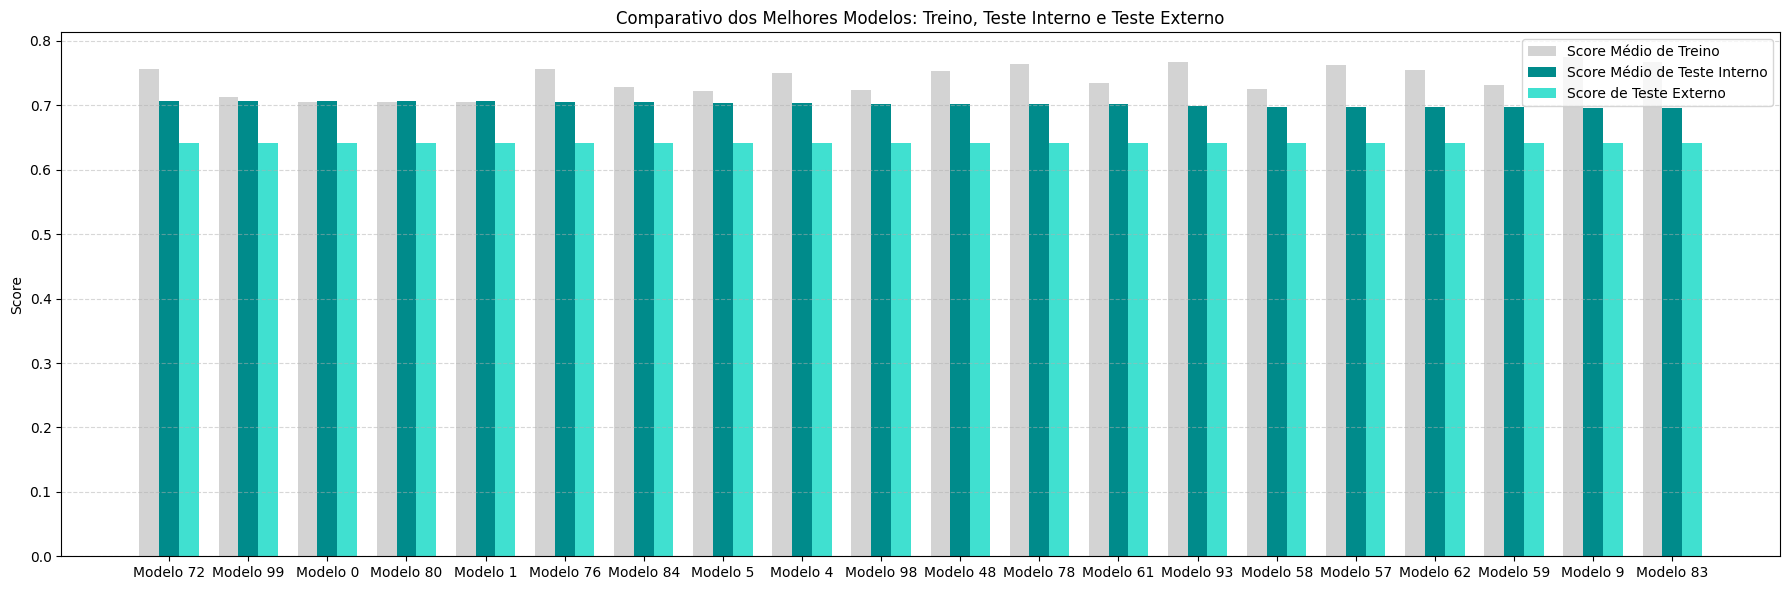

In [51]:
dados_grafico = resultados_filt_ord.head(20)     # Escolha quantos modelos quer exibir
x_pos = np.arange(len(dados_grafico))            # Posições dos rótulos do eixo X
largura_barra = 0.25                             # Largura das barras

plt.figure(figsize=(18, 6))
plt.bar(x_pos - largura_barra,                   # Série com score médio de treino
        dados_grafico["media_score_treino"],
        width=largura_barra,
        label="Score Médio de Treino",
        color="lightgray")
plt.bar(x_pos,                                   # Série com score médio de teste interno
        dados_grafico["media_score_teste_interno"],
        width=largura_barra,
        label="Score Médio de Teste Interno",
        color="darkcyan")
plt.bar(x_pos + largura_barra,                   # Série com score médio de teste externo
        dados_grafico["score_teste_externo"],
        width=largura_barra,
        label="Score de Teste Externo",
        color="turquoise")

plt.xticks(x_pos,
           dados_grafico["num_modelo"],
           rotation=0,
           ha='center')
plt.ylabel("Score")
plt.title("Comparativo dos Melhores Modelos: Treino, Teste Interno e Teste Externo")
plt.legend()
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

### **Etapa 7: Escolha do modelo**

*Escolha do modelo*

In [25]:
num_modelo_escolhido = "Modelo 346"

*Características do modelo escolhido*

In [26]:
linha = resultados.loc[resultados["num_modelo"] == num_modelo_escolhido].squeeze()
nome_algoritmo = linha["nome_algoritmo"]
hiperparametros = linha["hiperparametros"]
classe = algoritmos[nome_algoritmo][0]
print(f"O modelo final adotado foi construído com o algoritmo {nome_algoritmo}, com hiperparâmetros: { {k: round(v, 4) if isinstance(v, float) else v for k, v in hiperparametros.items()} }")

O modelo final adotado foi construído com o algoritmo ADABOOST, com hiperparâmetros: {'learning_rate': np.float64(0.0422), 'n_estimators': 260}


*Retreino do modelo no conjunto de treino completo*

In [27]:
modelo_final = classe.set_params(**hiperparametros)
modelo_final.fit(X_treino_tratada, y_treino, sample_weight=pesos_treino)

AdaBoostClassifier(learning_rate=np.float64(0.04218454832079112),
                   n_estimators=260, random_state=123)

### **Etapa 8: Calibração e análises adicionais no conjunto de teste externo**

*Aplicação do modelo final no conjunto de teste externo*

In [28]:
p_hat_teste = modelo_final.predict_proba(X_teste_tratada)
classes = modelo_final.classes_

*Atribuição da categoria de resposta predita pelo modelo, com base na maior probabilidade*

In [29]:
y_hat_teste = classes[p_hat_teste.argmax(axis=1)]

*Verificação gráfica de calibração das probabilidades*

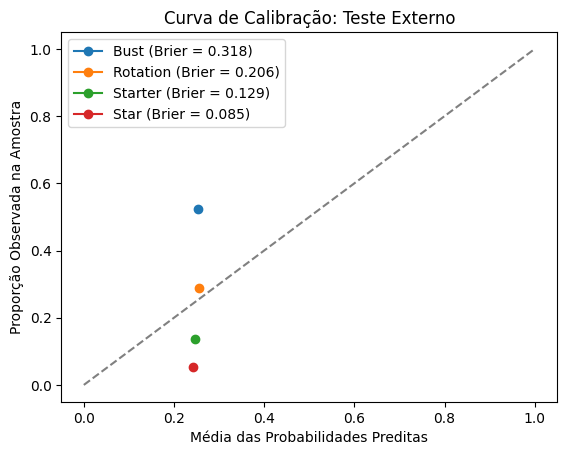

In [30]:
# Cálculos
y_one_hot = label_binarize(y_teste, classes=classes)

# Gráfico da curva de calibração para cada classe (one-versus-rest)
plt.plot([0,1],[0,1],'--', color='gray')
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    prop_obs, p_hat_media = calibration_curve(y_bin, p_hat_teste[:, k])
    brier = brier_score_loss(y_bin, p_hat_teste[:, k])
    plt.plot(p_hat_media,
             prop_obs,
             'o-',
             label=f"{ordem_categorias[cls]} (Brier = {brier:.3f})")
plt.xlabel("Média das Probabilidades Preditas")
plt.ylabel("Proporção Observada na Amostra")
plt.title("Curva de Calibração: Teste Externo")
plt.legend()
plt.show()

***(Se necessário)*** *Atualização de probabilidades preditas no teste, por meio de recalibração das probabilidades no conjunto de treino*

In [31]:
# Recalibração do modelo no treino - escolha o método: 'isotonic' (n > 1000) ou 'sigmoid'
modelo_final_calibrado = CalibratedClassifierCV(modelo_final, method='sigmoid', cv=5)
modelo_final_calibrado.fit(X_treino_tratada, y_treino)

# Armazenamento de probabilidades não calibradas e cálculo das probabilidades calibradas
p_hat_teste_nao_calibradas = p_hat_teste
p_hat_teste = modelo_final_calibrado.predict_proba(X_teste_tratada)

***(Se necessário)*** *Verificação gráfica de calibração das probabilidades - atualização pós calibração*

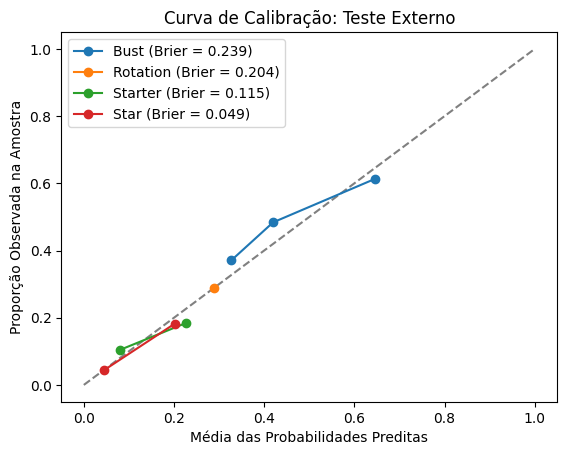

In [32]:
# Cálculos
y_one_hot = label_binarize(y_teste, classes=classes)

# Gráfico da curva de calibração para cada classe (one-versus-rest)
plt.plot([0,1],[0,1],'--', color='gray')
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    prop_obs, p_hat_media = calibration_curve(y_bin, p_hat_teste[:, k])
    brier = brier_score_loss(y_bin, p_hat_teste[:, k])
    plt.plot(p_hat_media,
             prop_obs,
             'o-',
             label=f"{ordem_categorias[cls]} (Brier = {brier:.3f})")
plt.xlabel("Média das Probabilidades Preditas")
plt.ylabel("Proporção Observada na Amostra")
plt.title("Curva de Calibração: Teste Externo")
plt.legend()
plt.show()

*Tabela de classificação*

In [33]:
# Tabela de classificação com frequências absolutas
tabela = pd.crosstab(y_teste, y_hat_teste)
tabela.index = np.asarray(ordem_categorias)[tabela.index]
tabela.columns = np.asarray(ordem_categorias)[tabela.columns]
tabela

,Bust,Starter,Star
Bust,65,14,21
Rotation,28,5,22
Starter,9,7,10
Star,4,2,4


In [34]:
# Tabela de classificação com frequências relativas, somando 100% em cada linha
tabela_relativa_linhas = (tabela.div(tabela.sum(axis=1), axis=0)).round(3)
tabela_relativa_linhas

,Bust,Starter,Star
Bust,0.650,0.140,0.210
Rotation,0.509,0.091,0.400
Starter,0.346,0.269,0.385
Star,0.400,0.200,0.400


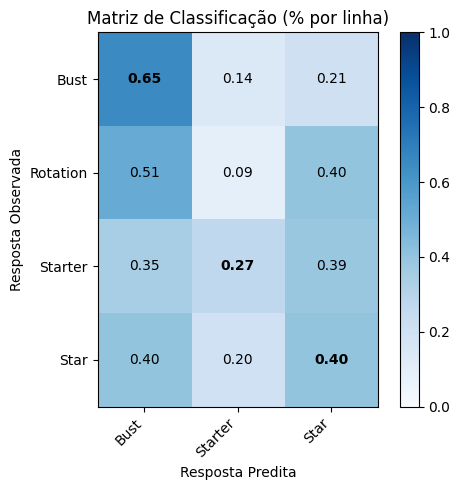

In [35]:
# Gráfico de calor com frequências relativas, somando 100% em cada linha
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(tabela_relativa_linhas.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(tabela_relativa_linhas.shape[1]))
ax.set_yticks(range(tabela_relativa_linhas.shape[0]))
ax.set_xticklabels(tabela_relativa_linhas.columns, rotation=45, ha='right')
ax.set_yticklabels(tabela_relativa_linhas.index)
ax.set_xlabel("Resposta Predita"); ax.set_ylabel("Resposta Observada")
ax.set_title("Matriz de Classificação (% por linha)")

for (i, j), v in np.ndenumerate(tabela_relativa_linhas.values):
    same_label = tabela_relativa_linhas.index[i] == tabela_relativa_linhas.columns[j]
    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
            fontweight=("bold" if same_label else "normal"))

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [36]:
# Tabela de classificação com frequências relativas, somando 100% em cada coluna
tabela_relativa_colunas = (tabela.div(tabela.sum(axis=0), axis=1)).round(3)
tabela_relativa_colunas

,Bust,Starter,Star
Bust,0.613,0.500,0.368
Rotation,0.264,0.179,0.386
Starter,0.085,0.250,0.175
Star,0.038,0.071,0.070


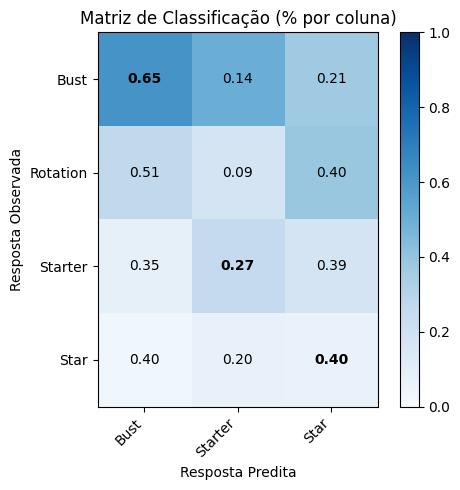

In [37]:
# Gráfico de calor com frequências relativas, somando 100% em cada coluna
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(tabela_relativa_colunas.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(tabela_relativa_colunas.shape[1]))
ax.set_yticks(range(tabela_relativa_colunas.shape[0]))
ax.set_xticklabels(tabela_relativa_colunas.columns, rotation=45, ha='right')
ax.set_yticklabels(tabela_relativa_colunas.index)
ax.set_xlabel("Resposta Predita"); ax.set_ylabel("Resposta Observada")
ax.set_title("Matriz de Classificação (% por coluna)")

for (i, j), v in np.ndenumerate(tabela_relativa_linhas.values):
    same_label = tabela_relativa_linhas.index[i] == tabela_relativa_linhas.columns[j]
    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
            fontweight=("bold" if same_label else "normal"))

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

*Desempenho: taxas de acerto por categoria, precisões por categoria, AUC-OVR, acurácia e acurácia balanceada*

In [38]:
# Taxas de acerto por categoria (recalls)
pd.Series(
    np.diag(tabela_relativa_linhas.reindex(columns=tabela_relativa_linhas.index).to_numpy()),
    index=tabela_relativa_linhas.index
)

Bust       0.650
Rotation     NaN
Starter    0.269
Star       0.400
dtype: float64

In [39]:
# Precisões por categoria
pd.Series(
    np.diag(tabela_relativa_colunas.reindex(columns=tabela_relativa_colunas.index).to_numpy()),
    index=tabela_relativa_colunas.index
)

Bust       0.613
Rotation     NaN
Starter    0.250
Star       0.070
dtype: float64

In [40]:
# AUC-OVR, acurácia e acurácia balanceada
auc_ovr = roc_auc_score(y_teste, p_hat_teste, multi_class='ovr', average='macro')
acuracia = accuracy_score(y_teste, y_hat_teste)
acuracia_balanceada = balanced_accuracy_score(y_teste, y_hat_teste)

print(f'AUC-OVR: {auc_ovr:.3f}')
print(f'Acurácia: {acuracia:.3f}')
print(f'Acurácia balanceada: {acuracia_balanceada:.3f}')

AUC-OVR: 0.639
Acurácia: 0.398
Acurácia balanceada: 0.330


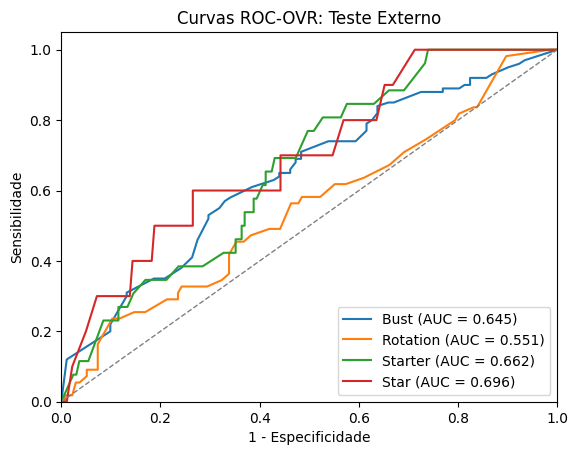

In [41]:
# Exibição das curvas ROC-OVR
plt.figure()
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    fpr, tpr, _ = roc_curve(y_bin, p_hat_teste[:, k])
    auc_k = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=1.5, label=f'{ordem_categorias[cls]} (AUC = {auc_k:.3f})')

plt.plot([0, 1], [0, 1], '--', color='gray', lw=1)
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel('1 - Especificidade'); plt.ylabel('Sensibilidade')
plt.title('Curvas ROC-OVR: Teste Externo')
plt.legend(loc="lower right")
plt.show()

### **Etapa 9: Interpretabilidade do modelo final**

*Cálculo da importância em redução de impureza para cada variável no modelo final (aplicável apenas para modelos baseados em árvores)*

In [42]:
# ATENÇÃO! Aplicável apenas caso o modelo final seja baseado em árvores, com exceção do gradient boosting com histogramas; caso contrário, resultará em erro
importancias_impureza = pd.Series(modelo_final.feature_importances_,
                                  index=X_treino_tratada.columns).sort_values()

*Gráfico de importâncias em redução de impureza (aplicável apenas para modelos baseados em árvores)*

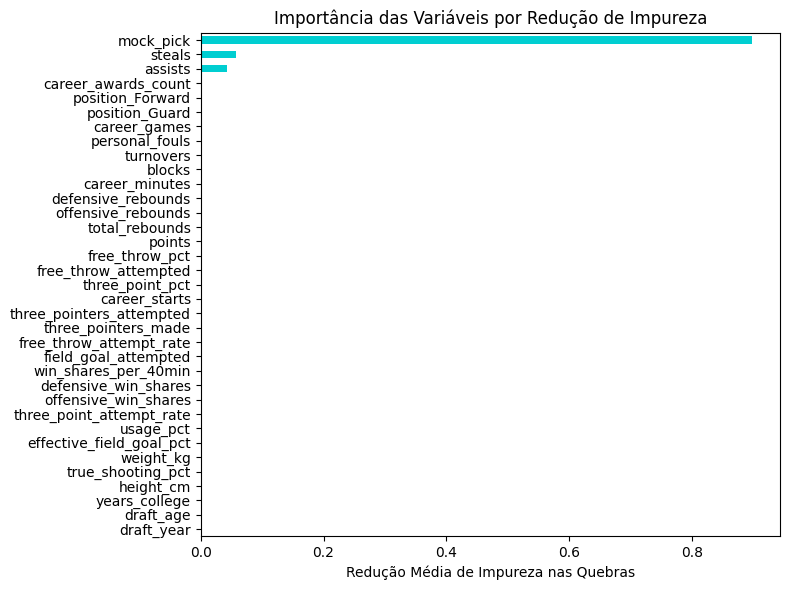

In [43]:
# ATENÇÃO! Aplicável apenas caso o modelo final seja baseado em árvores, com exceção do gradient boosting com histogramas; caso contrário, resultará em erro
plt.figure(figsize=(8, 6))
importancias_impureza.plot.barh(title="Importância das Variáveis por Redução de Impureza",
                                color="darkturquoise")
plt.xlabel("Redução Média de Impureza nas Quebras")
plt.tight_layout()
plt.show()

*Cálculo da importância por permutação para cada variável no modelo final*

In [44]:
importancias_permutacao = permutation_importance(modelo_final,
                                                 X_treino_tratada,
                                                 y_treino,
                                                 n_repeats=30,
                                                 random_state=123, 
                                                 scoring='roc_auc_ovr')
importancias_permutacao = pd.Series(importancias_permutacao.importances_mean,
                                    index=X_treino_tratada.columns).sort_values()

*Gráfico de importâncias por permutação*

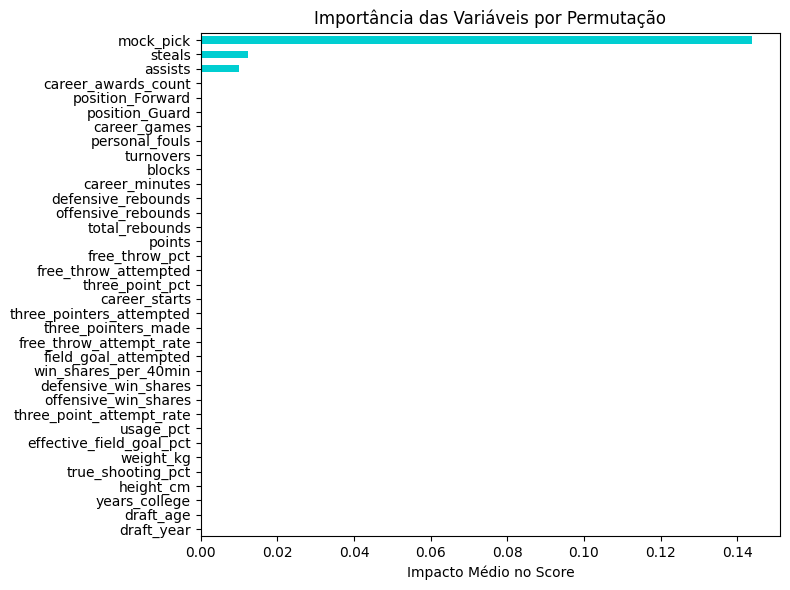

In [45]:
plt.figure(figsize=(8, 6))
importancias_permutacao.plot.barh(title="Importância das Variáveis por Permutação",
                                  color="darkturquoise")
plt.xlabel("Impacto Médio no Score")
plt.tight_layout()
plt.show()

*Cálculo dos valores SHAP das variáveis no modelo final*

In [46]:
if nome_algoritmo not in ['ADABOOST', 'GRADIENT BOOSTING', 'GRADIENT BOOSTING COM HISTOGRAMAS']:
    # Caso demore para rodar, especialmente em bases grandes, substitua X_treino_tratada.shape[0] por um número de tamanho de subamostra (ex.: 100)
    X_amostra = shap.sample(X_treino_tratada, X_treino_tratada.shape[0], random_state=123)
    explainer = shap.Explainer(modelo_final, X_amostra)
    valores_shap = explainer(X_amostra)
else:
    # Para AdaBoost, GB e GB com histogramas, a implementação do cálculo de valores SHAP no caso multinomial não é direta; é preciso usar um método mais oneroso computacionalmente, em uma subamostra pequena de observações
    X_amostra = shap.sample(X_treino_tratada, 100, random_state=123)
    explainer = shap.Explainer(modelo_final.predict_proba, X_amostra)
    valores_shap = explainer(X_amostra)

# Obs. Caso haja algum erro de atividade ("additivity"), acrescente o seguinte argumento na função 'explainer': check_additivity=False

PermutationExplainer explainer: 101it [02:31,  1.53s/it]                         


*Gráfico de valores absolutos médios de SHAP*

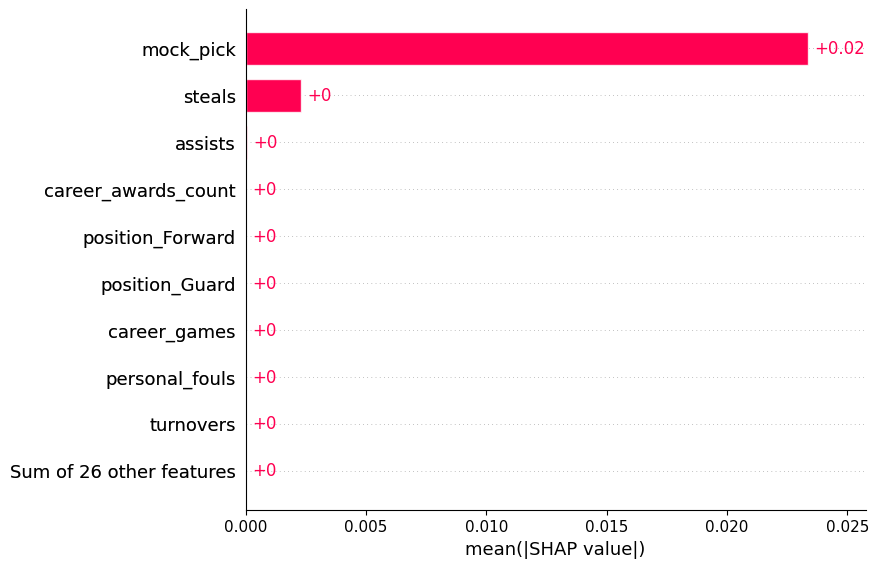

In [47]:
shap.plots.bar(valores_shap[:,:,0])    # ATENÇÃO: Altere o último valor dentro dos colchetes (0, 1, 2, ...) para alternar entras as diferentes categorias de resposta

*Gráfico de direção do impacto baseado em SHAP (beeswarm)*

C:\Users\caio\AppData\Local\Temp\ipykernel_14256\1522158444.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(valores_shap[:,:,0], max_display=10)    # ATENÇÃO: Altere o último valor dentro dos colchetes (0, 1, 2, ...) para alternar entras as diferentes categorias de resposta


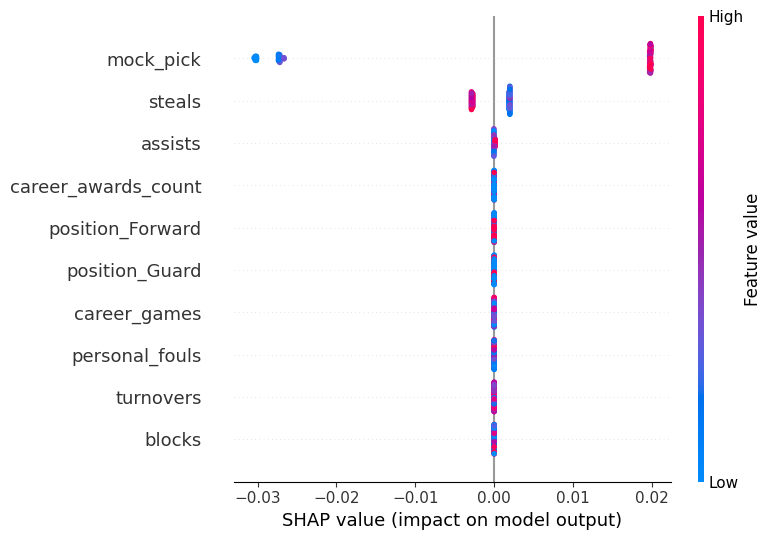

In [48]:
shap.summary_plot(valores_shap[:,:,0], max_display=10)    # ATENÇÃO: Altere o último valor dentro dos colchetes (0, 1, 2, ...) para alternar entras as diferentes categorias de resposta